# 🏗️ Building Age Classification from Satellite Imagery

# Notebook 7 — Decision Evidence & Leakage Audit

---

Notebooks 5 and 6 build the final pipeline. This notebook is the **proof file**: every modelling decision is
re-tested here against the alternative it replaced, with the code, a table and a chart, so any choice can be
defended by pointing to a cell. The data-level decisions (haze filter, median compositing, city-year anomaly,
spatial clustering) are proven inside Notebook 5 (Sections 5.2b, 5.4b, 5.6b).

| Section | Decision | Alternative tested |
|---------|----------|--------------------|
| 7.2 | LightGBM as the Stage 1 model | Random Forest (Notebooks 3-4) |
| 7.3 | `class_weight='balanced'` | No class weights |
| 7.4 | Feature groups (anomaly, change, meta, spatial) | Notebook 3's 60 features, and each group added in turn |
| 7.5 | Per-city standardisation | One scaler fitted on Madrid (Notebook 3) |
| 7.6 | Stage 2 ensemble design | Recalibration only, single learners, other boosting lengths, prototype weights, self-training |
| 7.7 | — | **Leakage audit**: label leakage, fit-scope leakage, few-shot overlap, spatial leakage (blocked CV with maps) |
| 7.8 | — | Summary table: each decision → its evidence |

**Protocol.** Unless stated otherwise: Madrid scores are macro F1 from 3-fold stratified CV (seed 42) with the
Stage 1 hyper-parameters of Notebook 6; Amsterdam few-shot scores use Notebook 6's protocol (support drawn only from
training folds, the held-out fold is the test set). Running everything takes about 1.5-2 hours on 2 CPU cores.

## 7.1 Setup

In [1]:
import gc, json, os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.ndimage import maximum_filter
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score, recall_score
warnings.filterwarnings('ignore', category=UserWarning)

DATA_DIR = Path('data') if Path('data/features').exists() else Path('../data')
FEAT_DIR = DATA_DIR / 'features'
OUT_DIR  = Path('results'); OUT_DIR.mkdir(exist_ok=True)

SEED = 42
QUICK_RUN = os.environ.get('H4D_QUICK', '0') == '1'   # smoke test only; reported numbers use QUICK_RUN = False

# Stage 1 hyper-parameters: identical to Notebook 6, Section 6.3
STAGE1_PARAMS = dict(n_estimators=700, learning_rate=0.05, num_leaves=63, min_child_samples=40,
                     subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                     class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1)
RF_TREES = 500                                         # Notebook 4's Random Forest size
AMS_REPEATS = 2
if QUICK_RUN:
    STAGE1_PARAMS['n_estimators'] = 60; RF_TREES = 40; AMS_REPEATS = 1
    print('QUICK_RUN: reduced trees and repeats - numbers are NOT the reported results')

CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
f1m = lambda y, p: f1_score(y, p, average='macro')
plt.rcParams['figure.dpi'] = 100

groups = json.load(open(FEAT_DIR / 'feature_groups.json'))
G = lambda *names: [c for g in names for c in groups[g]]
SETS = {'baseline (NB3, 60)':      G('baseline'),
        '+ anomaly, change, meta': G('baseline', 'anomaly', 'change', 'meta'),
        '+ spatial v1':            G('baseline', 'anomaly', 'change', 'meta', 'spatial_v1'),
        '+ spatial v2 (final)':    G('baseline', 'anomaly', 'change', 'meta', 'spatial_v1', 'spatial')}
ALL, CORE, BASE = SETS['+ spatial v2 (final)'], SETS['+ anomaly, change, meta'], SETS['baseline (NB3, 60)']

mad = pd.read_parquet(FEAT_DIR / 'features_madrid.parquet')
ams = pd.read_parquet(FEAT_DIR / 'features_amsterdam.parquet')
y_mad, y_ams = mad['age_class'].values.astype(int), ams['age_class'].values.astype(int)
pix_mad, pix_ams = mad[['px_key', 'py_key']].values, ams[['px_key', 'py_key']].values

# ── Scaling: per-city robust standardisation (Notebook 6, Section 6.2) and Notebook 3's Madrid scaler ──
def robust_stats(X):
    med = np.median(X, 0); iqr = np.percentile(X, 75, 0) - np.percentile(X, 25, 0)
    return med, np.where(iqr < 1e-6, X.std(0) + 1e-6, iqr)
def apply_stats(X, st):
    return np.clip((X - st[0]) / st[1], -10, 10).astype(np.float32)
def city_standardise(X):
    X = np.asarray(X, np.float32); return apply_stats(X, robust_stats(X))

def scaled(cols, scaling='city'):
    '''Madrid and Amsterdam matrices for a column list. scaling = 'city' (ours) or 'madrid' (Notebook 3).'''
    Xm, Xa = mad[cols].values.astype(np.float32), ams[cols].values.astype(np.float32)
    if scaling == 'city':
        return city_standardise(Xm), city_standardise(Xa)
    sc = StandardScaler().fit(Xm)                     # fitted on Madrid, applied to both cities
    return sc.transform(Xm).astype(np.float32), sc.transform(Xa).astype(np.float32)

RAND3 = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(np.zeros(len(y_mad)), y_mad))
print(f'Madrid {len(y_mad):,} px, Amsterdam {len(y_ams):,} px; feature sets: ' +
      ', '.join(f'{k}={len(v)}' for k, v in SETS.items()))

Madrid 76,263 px, Amsterdam 25,992 px; feature sets: baseline (NB3, 60)=60, + anomaly, change, meta=179, + spatial v1=199, + spatial v2 (final)=284


In [2]:
# ── Shared helpers ─────────────────────────────────────────────────────────────
def cv_run(model_fn, X, y, splits, label=''):
    '''Fit model_fn() on each training fold, score macro F1 on the test fold. Pools out-of-fold predictions.'''
    t0, scores, yt, yp = time.time(), [], [], []
    for tr, te in splits:
        m = model_fn().fit(X[tr], y[tr]); p = m.predict(X[te])
        scores.append(f1m(y[te], p)); yt.append(y[te]); yp.append(p)
    r = dict(mean=float(np.mean(scores)), std=float(np.std(scores)), folds=scores,
             y_true=np.concatenate(yt), y_pred=np.concatenate(yp))
    print(f'  {label:45s} macro F1 = {r["mean"]:.4f} ± {r["std"]:.4f}   [{time.time()-t0:.0f}s]')
    return r

lgbm = lambda **kw: (lambda: lgb.LGBMClassifier(**{**STAGE1_PARAMS, **kw}))
class ChunkedForest:
    '''
    Notebook 4's Random Forest (RF_TREES trees, balanced weights), grown 100 trees at a time.
    A forest's prediction is the average of its trees' class probabilities, so averaging the probabilities of
    five 100-tree forests (different seeds) is the same model as one 500-tree forest. Growing it in chunks
    and freeing each chunk after predicting keeps memory under the 7 GB of this machine (one fully grown
    500-tree forest on 80 % of Madrid needs more than 6 GB and was killed by the OS in our first run).
    '''
    def fit(self, X, y): self.X, self.y = X, y; return self
    def predict(self, Xt):
        proba = 0
        for k in range(0, RF_TREES, 100):
            m = RandomForestClassifier(n_estimators=min(100, RF_TREES - k), class_weight='balanced',
                                       random_state=SEED + k, n_jobs=-1).fit(self.X, self.y)
            proba = proba + m.predict_proba(Xt) * m.n_estimators; classes = m.classes_
            del m; gc.collect()
        return classes[np.argmax(proba, 1)]
rf   = lambda: ChunkedForest()

def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def adapt_to_city(stage1, X_city, support_idx, y_support, n, seed=SEED,
                  rounds_per_label=3, proto_weight='fade', learners=('proto', 'lr', 'boost'), lr_inputs='both'):
    '''
    Stage 2 transfer. With the DEFAULT arguments this is exactly Notebook 6's adapt_to_city (Section 6.7) with
    smoothing off (alpha = 0 was selected there); this is checked numerically in Section 7.6.
    The extra arguments only exist to test the alternatives we rejected:
      rounds_per_label : boosting rounds = 20 + rounds_per_label * n            (final: 3)
      proto_weight     : 'fade' = max(0, 1 - n/100), 'equal' = 1, 'none' = 0   (final: 'fade')
      learners         : which learners are averaged                           (final: all three)
      lr_inputs        : 'both' = Madrid log-probs + 40 features, 'logprob' = recalibration only
    '''
    raw = stage1.predict(X_city, raw_score=True)
    lp  = np.log(_softmax(raw) + 1e-6)
    top = np.argsort(stage1.booster_.feature_importance('gain'))[::-1][:40]       # chosen on Madrid only
    Z   = X_city[:, top]
    parts, weights = {}, {}
    if 'boost' in learners:
        bp = dict(objective='multiclass', num_class=4, learning_rate=0.05, num_leaves=7,
                  min_data_in_leaf=max(3, n // 5), feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=5.0, verbose=-1, seed=seed, num_threads=2)
        rounds = int(min(20 + rounds_per_label * n, 400))
        b = lgb.train(bp, lgb.Dataset(X_city[support_idx], y_support - 1,
                                      init_score=raw[support_idx].ravel(order='F')), rounds)
        parts['boost'] = _softmax(raw + b.predict(X_city, raw_score=True)); weights['boost'] = 1.0
    if 'lr' in learners:
        S  = lp if lr_inputs == 'logprob' else np.hstack([lp, Z])
        sc = StandardScaler().fit(S[support_idx])
        Cr = 0.05 if n <= 5 else 0.1 if n <= 25 else 0.3
        parts['lr'] = LogisticRegression(C=Cr, max_iter=5000).fit(sc.transform(S[support_idx]), y_support) \
                                                              .predict_proba(sc.transform(S))
        weights['lr'] = 1.0
    if 'proto' in learners:
        protos = np.stack([Z[support_idx][y_support == c].mean(0) for c in (1, 2, 3, 4)])
        d = np.sqrt(((Z[:, None, :] - protos[None]) ** 2).sum(-1))
        parts['proto'] = _softmax(-d / np.sqrt(Z.shape[1]) * 4)
        weights['proto'] = {'fade': max(0.0, 1 - n / 100), 'equal': 1.0, 'none': 0.0}[proto_weight]
        if len(learners) == 1: weights['proto'] = 1.0
    tot = sum(weights.values())
    return sum(weights[k] * parts[k] for k in parts) / tot

def fewshot_splits(y, n, n_folds=5, n_repeats=AMS_REPEATS, seed=SEED, groups=None, pix=None, buffer=0):
    '''Notebook 6's protocol. With groups (+pix, buffer) the folds are spatial blocks (Section 7.7).'''
    rng = np.random.default_rng(seed)
    for rep in range(n_repeats):
        if groups is None:
            sp = StratifiedKFold(n_folds, shuffle=True, random_state=seed + rep).split(np.zeros(len(y)), y)
        else:
            sp = StratifiedGroupKFold(n_folds, shuffle=True, random_state=seed + rep).split(np.zeros(len(y)), y, groups)
        for tr, te in sp:
            if buffer: tr = tr[~near_mask(pix, te, buffer)[tr]]
            sup = np.concatenate([rng.choice(tr[y[tr] == c], n, replace=False) for c in (1, 2, 3, 4)])
            yield sup, te

def fewshot_score(stage1, Xa, n, **kw):
    split_kw = {k: kw.pop(k) for k in ('groups', 'pix', 'buffer', 'n_repeats') if k in kw}
    s = [f1m(y_ams[te], adapt_to_city(stage1, Xa, sup, y_ams[sup], n, **kw)[te].argmax(1) + 1)
         for sup, te in fewshot_splits(y_ams, n, **split_kw)]
    return float(np.mean(s)), float(np.std(s))

def near_mask(pix, test_idx, buffer):
    '''True for pixels within `buffer` grid cells (Chebyshev distance) of any test pixel.'''
    x, y = pix[:, 0] - pix[:, 0].min(), pix[:, 1] - pix[:, 1].min()
    g = np.zeros((y.max() + 1, x.max() + 1), bool); g[y[test_idx], x[test_idx]] = True
    return maximum_filter(g, size=2 * buffer + 1)[y, x]

def to_grid(pix, values):
    x = (pix[:, 0] - pix[:, 0].min()).astype(int); y = (pix[:, 1] - pix[:, 1].min()).astype(int)
    g = np.full((y.max() + 1, x.max() + 1), np.nan, np.float32); g[y, x] = values
    return g

E = {}            # every number the summary table (7.8) quotes is stored here
print('helpers ready')

helpers ready


---

## 7.2 Decision: LightGBM instead of Random Forest

**Claim.** On *the same* 60 Notebook 3 features, gradient boosting beats the Random Forest used in Notebooks 3-4.
Testing on identical features isolates the model choice from the feature work. Both models use balanced class
weights so only the algorithm differs. Trees ignore feature scaling, so scaling plays no part here.

Madrid 3-fold CV, 60 baseline features:


  Random Forest (500 trees)                     macro F1 = 0.6367 ± 0.0055   [234s]


  LightGBM (Stage 1 parameters)                 macro F1 = 0.6512 ± 0.0043   [66s]


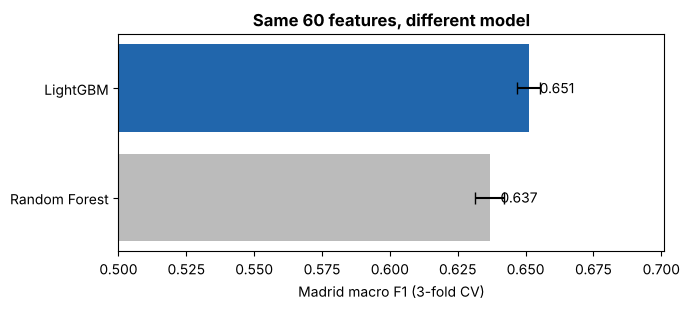

LightGBM gain over Random Forest: +0.0144


In [3]:
Xb_m, _ = scaled(BASE, 'madrid')
print('Madrid 3-fold CV, 60 baseline features:')
E['rf_base']   = cv_run(rf, Xb_m, y_mad, RAND3, f'Random Forest ({RF_TREES} trees)')
E['lgbm_base'] = cv_run(lgbm(), Xb_m, y_mad, RAND3, 'LightGBM (Stage 1 parameters)')

fig, ax = plt.subplots(figsize=(7, 3.2))
names = ['Random Forest', 'LightGBM']
vals  = [E['rf_base'], E['lgbm_base']]
ax.barh(names, [v['mean'] for v in vals], xerr=[v['std'] for v in vals], color=['#bbbbbb', '#2166ac'], capsize=4)
for i, v in enumerate(vals): ax.text(v['mean'] + 0.004, i, f"{v['mean']:.3f}", va='center')
ax.set_xlim(0.5, max(v['mean'] for v in vals) + 0.05); ax.set_xlabel('Madrid macro F1 (3-fold CV)')
ax.set_title('Same 60 features, different model', fontweight='bold')
plt.tight_layout(); plt.show()
print(f"LightGBM gain over Random Forest: {E['lgbm_base']['mean'] - E['rf_base']['mean']:+.4f}")

**Result.** On identical inputs LightGBM scores **0.6512 ± 0.0043** against the Random Forest's **0.6367 ± 0.0055**
(+0.014, about three fold-standard-deviations), and trains in a quarter of the time (66 s vs 234 s for 3 folds).
It also has a practical advantage the Random Forest lacks: it can **continue training from a starting score**
(`init_score`), which is how Stage 2 fine-tunes the Madrid model on Amsterdam labels (Section 7.6).

---

## 7.3 Decision: balanced class weights

**Claim.** Without weights, the model favours the largest class (class 2 in Madrid: 36% of pixels) and loses
recall on the smallest ones, which lowers **macro** F1 because every class counts equally. Same features (all 284),
same folds; only `class_weight` changes.

Madrid 3-fold CV, all 284 features:


  class_weight='balanced' (final)               macro F1 = 0.7746 ± 0.0025   [231s]


  no class weights                              macro F1 = 0.7722 ± 0.0033   [234s]


,no weights,balanced (final),change
C1 (18% of pixels),0.6665,0.7225,0.0560
C2 (36% of pixels),0.8434,0.8013,-0.0421
C3 (24% of pixels),0.7325,0.7453,0.0128
C4 (22% of pixels),0.8010,0.8108,0.0098
macro F1,0.7722,0.7746,0.0025


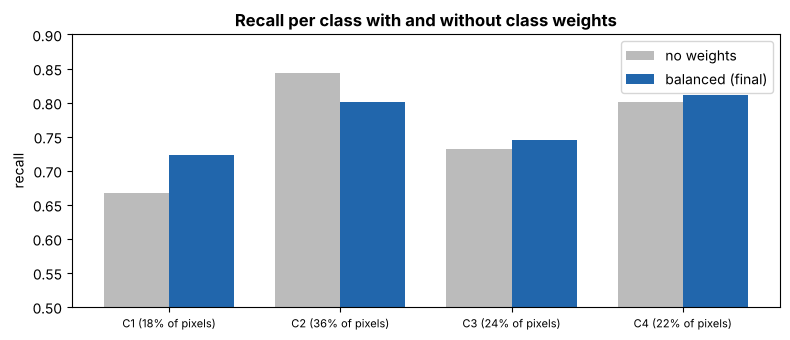

In [4]:
X_m, X_a = scaled(ALL, 'city')
print('Madrid 3-fold CV, all 284 features:')
E['all_bal']   = cv_run(lgbm(), X_m, y_mad, RAND3, "class_weight='balanced' (final)")
E['all_nobal'] = cv_run(lgbm(class_weight=None), X_m, y_mad, RAND3, 'no class weights')

rec = pd.DataFrame({k: recall_score(E[v]['y_true'], E[v]['y_pred'], labels=[1, 2, 3, 4], average=None)
                    for k, v in [('no weights', 'all_nobal'), ('balanced (final)', 'all_bal')]},
                   index=[f'C{c} ({(y_mad == c).mean():.0%} of pixels)' for c in (1, 2, 3, 4)])
rec.loc['macro F1'] = [E['all_nobal']['mean'], E['all_bal']['mean']]
rec['change'] = rec['balanced (final)'] - rec['no weights']
display(rec.style.format('{:.4f}').set_caption('Per-class recall (rows C1-C4) and macro F1'))

fig, ax = plt.subplots(figsize=(8, 3.5))
w = 0.38
ax.bar(np.arange(4) - w / 2, rec['no weights'][:4], w, color='#bbbbbb', label='no weights')
ax.bar(np.arange(4) + w / 2, rec['balanced (final)'][:4], w, color='#2166ac', label='balanced (final)')
ax.set_xticks(range(4)); ax.set_xticklabels(rec.index[:4], fontsize=8); ax.set_ylabel('recall'); ax.legend()
ax.set_ylim(0.5, 0.9); ax.set_title('Recall per class with and without class weights', fontweight='bold')
plt.tight_layout(); plt.show()

**Result — an honest one.** The effect on the headline metric is small: macro F1 **0.7746** balanced vs
**0.7722** unweighted (+0.0025, about one fold-standard-deviation, so not clearly significant on its own). What
balancing does do is shift recall exactly as claimed: class 1 (the smallest) gains **+5.6 points** of recall and the
dominant class 2 loses 4.2. We keep it because it is free, never lowers macro F1, and protects the rarest era —
the class that zero-shot transfer misses most in Amsterdam (Notebook 6). But it is not one of the decisions that
drives the score.

---

## 7.4 Decision: the feature groups (ablation)

**Claim.** Each feature group of Notebook 5 adds accuracy in Madrid **and** helps transfer to Amsterdam. Groups are
added one at a time. For each set we report Madrid 3-fold CV, zero-shot Amsterdam (Madrid model, no labels) and
25-shot Amsterdam (Stage 2 with 25 labels per class, 5-fold protocol). Per-city scaling is used throughout.

## 7.5 Decision: per-city standardisation

**Claim.** A scaler fitted on Madrid and applied to Amsterdam (Notebook 3) carries Madrid's scale into Amsterdam.
Tree models are unaffected by rescaling *within* one city, so Madrid CV is the same under both schemes; the
difference shows up only on Amsterdam. We test both scalings on the baseline and on the final feature set.

In [5]:
abl_rows, models = [], {}
for name, cols in SETS.items():
    print(f'\n[{name}] {len(cols)} features')
    Xm, Xa = scaled(cols, 'city')
    cvr = E['all_bal'] if name == '+ spatial v2 (final)' else \
          (E['lgbm_base'] if name == 'baseline (NB3, 60)' else cv_run(lgbm(), Xm, y_mad, RAND3, 'Madrid CV'))
    t0 = time.time()
    m = lgb.LGBMClassifier(**STAGE1_PARAMS).fit(Xm, y_mad); models[name] = m       # full-Madrid model
    for scaling in (['city', 'madrid'] if name in ('baseline (NB3, 60)', '+ spatial v2 (final)') else ['city']):
        Xa_s = Xa if scaling == 'city' else scaled(cols, 'madrid')[1]
        zs   = f1m(y_ams, m.predict(Xa_s))
        s25  = fewshot_score(m, Xa_s, 25, n_repeats=1)
        abl_rows.append({'feature set': name, 'n features': len(cols), 'scaling': scaling,
                         'Madrid CV': cvr['mean'], 'zero-shot': zs, '25-shot': s25[0]})
        print(f'  scaling={scaling:6s}: zero-shot {zs:.4f}   25-shot {s25[0]:.4f} ± {s25[1]:.4f}   [{time.time()-t0:.0f}s]')

abl = pd.DataFrame(abl_rows)
E['ablation'] = abl
display(abl[abl.scaling == 'city'].drop(columns='scaling').set_index('feature set')
        .style.format({'Madrid CV': '{:.4f}', 'zero-shot': '{:.4f}', '25-shot': '{:.4f}'})
        .set_caption('7.4 Ablation (per-city scaling)'))
sc_tab = abl[abl['feature set'].isin(['baseline (NB3, 60)', '+ spatial v2 (final)'])] \
            .pivot(index='feature set', columns='scaling', values=['zero-shot', '25-shot'])
display(sc_tab.style.format('{:.4f}').set_caption('7.5 Madrid scaler vs per-city scaling (Amsterdam)'))
abl.to_csv(OUT_DIR / 'evidence_ablation.csv', index=False)


[baseline (NB3, 60)] 60 features


  scaling=city  : zero-shot 0.4447   25-shot 0.6537 ± 0.0098   [53s]


  scaling=madrid: zero-shot 0.3995   25-shot 0.6458 ± 0.0107   [78s]

[+ anomaly, change, meta] 179 features


  Madrid CV                                     macro F1 = 0.6842 ± 0.0042   [146s]


  scaling=city  : zero-shot 0.4602   25-shot 0.6660 ± 0.0086   [78s]

[+ spatial v1] 199 features


  Madrid CV                                     macro F1 = 0.7336 ± 0.0049   [160s]


  scaling=city  : zero-shot 0.4903   25-shot 0.6917 ± 0.0100   [88s]

[+ spatial v2 (final)] 284 features


  scaling=city  : zero-shot 0.4856   25-shot 0.6942 ± 0.0129   [114s]


  scaling=madrid: zero-shot 0.5058   25-shot 0.6933 ± 0.0132   [143s]


,n features,Madrid CV,zero-shot,25-shot
feature set,,,,
"baseline (NB3, 60)",60,0.6512,0.4447,0.6537
"+ anomaly, change, meta",179,0.6842,0.4602,0.6660
+ spatial v1,199,0.7336,0.4903,0.6917
+ spatial v2 (final),284,0.7746,0.4856,0.6942


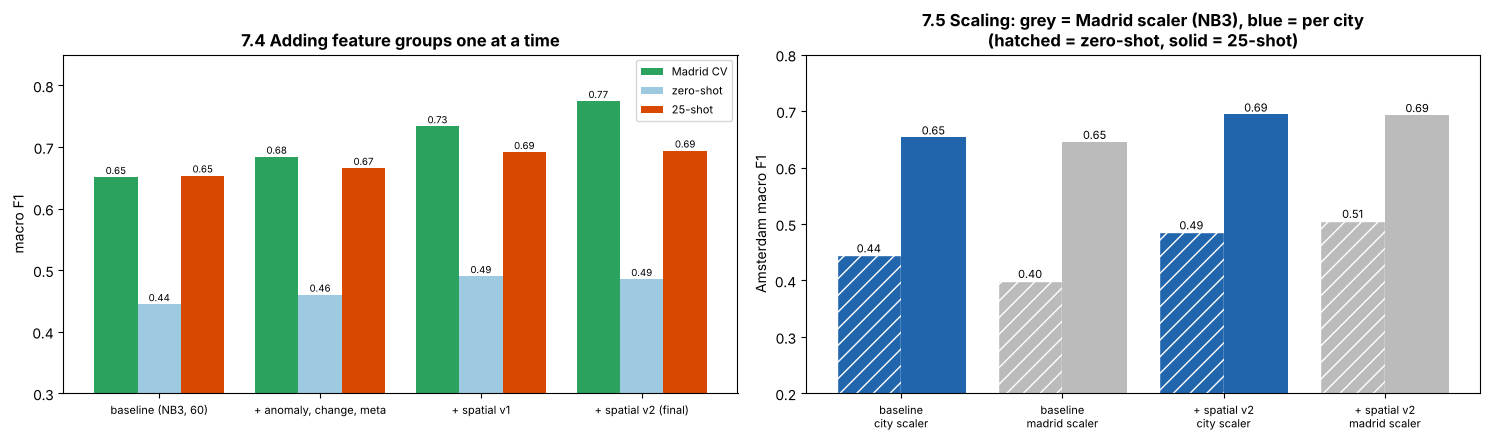

In [6]:
a = abl[abl.scaling == 'city']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(a)); w = 0.27
for i, (col, c) in enumerate([('Madrid CV', '#2ca25f'), ('zero-shot', '#9ecae1'), ('25-shot', '#d94801')]):
    axes[0].bar(x + (i - 1) * w, a[col], w, color=c, label=col)
    for xi, v in zip(x, a[col]): axes[0].text(xi + (i - 1) * w, v + 0.005, f'{v:.2f}', ha='center', fontsize=7)
axes[0].set_xticks(x); axes[0].set_xticklabels(a['feature set'], fontsize=8)
axes[0].set_ylabel('macro F1'); axes[0].set_ylim(0.3, 0.85); axes[0].legend(fontsize=8)
axes[0].set_title('7.4 Adding feature groups one at a time', fontweight='bold')

b = abl[abl['feature set'].isin(['baseline (NB3, 60)', '+ spatial v2 (final)'])]
lab = [f"{r['feature set'].split(' (')[0]}\n{r['scaling']} scaler" for _, r in b.iterrows()]
cols = ['#2166ac' if s == 'city' else '#bbbbbb' for s in b.scaling]
xb = np.arange(len(b))
axes[1].bar(xb - 0.2, b['zero-shot'], 0.4, color=cols, hatch='//', edgecolor='white', label='zero-shot')
axes[1].bar(xb + 0.2, b['25-shot'], 0.4, color=cols, label='25-shot')
for xi, (z, s) in enumerate(zip(b['zero-shot'], b['25-shot'])):
    axes[1].text(xi - 0.2, z + 0.005, f'{z:.2f}', ha='center', fontsize=8)
    axes[1].text(xi + 0.2, s + 0.005, f'{s:.2f}', ha='center', fontsize=8)
axes[1].set_xticks(xb); axes[1].set_xticklabels(lab, fontsize=8); axes[1].set_ylim(0.2, 0.8)
axes[1].set_ylabel('Amsterdam macro F1')
axes[1].set_title('7.5 Scaling: grey = Madrid scaler (NB3), blue = per city\n(hatched = zero-shot, solid = 25-shot)',
                  fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'evidence_ablation.png', bbox_inches='tight', dpi=130); plt.show()

**Reading the ablation.**

* **Madrid:** every group helps — 0.651 (Notebook 3 features) → 0.684 (+ anomaly, change, meta) → 0.734 (+ spatial v1)
  → 0.775 (+ spatial v2), a total gain of **+0.123**.
* **Amsterdam 25-shot:** 0.654 → 0.666 → 0.692 → 0.694. The anomaly block and the first spatial group carry the
  transfer gain (+0.038 together); the extra spatial-v2 radii add **almost nothing for transfer (+0.003)** and
  slightly lower zero-shot (0.490 → 0.486). Their benefit is mainly in Madrid, and Section 7.7 shows part of it is
  spatial optimism of random folds.

**Reading the scaling test — mixed evidence, stated plainly.**

* On Notebook 3's 60 features, per-city scaling clearly beats the Madrid scaler: zero-shot **0.445 vs 0.399**,
  25-shot 0.654 vs 0.646. Raw reflectance carries each city's level, and only per-city scaling removes it.
* On the final 284 features the advantage disappears: 25-shot is equal (**0.6942 vs 0.6933**), and the Madrid scaler
  is actually **better for zero-shot (0.506 vs 0.486)**. The city-year anomaly (Notebook 5) already removes the city
  level, so per-city scaling has little left to fix, and stretching Amsterdam onto its own IQR slightly distorts what
  the Madrid model learned.
* We keep per-city scaling because the target use is few-shot, where the two are tied, and it needs no statistics
  from another city. If zero-shot (no labels at all) were the goal, the Madrid scaler would be the better choice.

---

## 7.6 Decision: the Stage 2 transfer design

All variants below start from the **same** final Madrid model (all 284 features, per-city scaling) and use the
**same** Amsterdam splits (5 folds × 2 repeats). Only the transfer step changes.

| Variant | What it tests |
|---------|---------------|
| zero-shot | no labels at all (lower bound) |
| recalibration only | logistic regression on the 4 Madrid log-probabilities only (the simplest few-shot fix) |
| prototypes / logistic regression / boosting alone | each learner of the ensemble on its own |
| boosting 20+1.5n / 20+6n rounds | half and double the boosting length used (20+3n) |
| prototypes weight equal / none | instead of the fading weight max(0, 1 − n/100) |
| self-training | add the 500 most confident unlabelled pixels per class as pseudo-labels, refit |
| **final** | Notebook 6's `adapt_to_city` |

First, a numerical check that this notebook's `adapt_to_city` with default arguments reproduces Notebook 6.

In [7]:
stage1, X_a = models['+ spatial v2 (final)'], scaled(ALL, 'city')[1]
rng = np.random.default_rng(SEED)
sup = np.concatenate([rng.choice(np.where(y_ams == c)[0], 25, replace=False) for c in (1, 2, 3, 4)])
rest = np.setdiff1d(np.arange(len(y_ams)), sup)
p = adapt_to_city(stage1, X_a, sup, y_ams[sup], 25)
f1_here = f1m(y_ams[rest], p[rest].argmax(1) + 1)
print(f'n = 25 example (same seed and support as Notebook 6, Section 6.7): macro F1 = {f1_here:.4f}')
try:
    nb6 = json.load(open('6-Improved_Modelling_and_Transfer.ipynb'))
    txt = ''.join(''.join(o.get('text', '')) for c in nb6['cells'] if c['cell_type'] == 'code'
                  for o in c.get('outputs', []))
    import re
    m = re.search(r'Example n=25: macro F1 on the other [\d,]+ Amsterdam pixels = ([\d.]+)', txt)
    print(f'Notebook 6 printed:                                              macro F1 = {m.group(1)}'
          if m else 'Notebook 6 output not found (run Notebook 6 first to compare).')
except FileNotFoundError:
    print('Notebook 6 not found next to this notebook.')

n = 25 example (same seed and support as Notebook 6, Section 6.7): macro F1 = 0.6785
Notebook 6 printed:                                              macro F1 = 0.6785


In [8]:
def self_training(stage1, Xa, sup, ysup, n, k=500):
    # pseudo-label the k most confident non-support pixels per class, then refit with them added
    p = adapt_to_city(stage1, Xa, sup, ysup, n)
    conf, pred = p.max(1), p.argmax(1) + 1
    free = np.ones(len(p), bool); free[sup] = False
    extra = np.concatenate([np.where(free & (pred == c))[0][np.argsort(-conf[free & (pred == c)])[:k]]
                            for c in (1, 2, 3, 4)])
    return adapt_to_city(stage1, Xa, np.r_[sup, extra], np.r_[ysup, pred[extra]], n)

VARIANTS = {
    'recalibration only':          dict(learners=('lr',), lr_inputs='logprob'),
    'prototypes alone':            dict(learners=('proto',)),
    'logistic regression alone':   dict(learners=('lr',)),
    'boosting alone':              dict(learners=('boost',)),
    'boosting 20+1.5n rounds':     dict(rounds_per_label=1.5),
    'boosting 20+6n rounds':       dict(rounds_per_label=6),
    'prototype weight = equal':    dict(proto_weight='equal'),
    'prototype weight = none':     dict(proto_weight='none'),
    'final (Notebook 6)':          dict(),
}
BUDGETS = [5, 25, 100, 200]
var = {k: {} for k in ['zero-shot'] + list(VARIANTS) + ['self-training']}
zs = f1m(y_ams, stage1.predict(X_a))
t0 = time.time()
for n in BUDGETS:
    var['zero-shot'][n] = (zs, 0.0)
    for name, kw in VARIANTS.items():
        var[name][n] = fewshot_score(stage1, X_a, n, **kw)
    s = [f1m(y_ams[te], self_training(stage1, X_a, sup, y_ams[sup], n)[te].argmax(1) + 1)
         for sup, te in fewshot_splits(y_ams, n)]
    var['self-training'][n] = (float(np.mean(s)), float(np.std(s)))
    print(f'  n = {n:3d} done [{time.time()-t0:.0f}s]')

vt = pd.DataFrame({name: [f'{var[name][n][0]:.4f} ± {var[name][n][1]:.4f}' for n in BUDGETS] for name in var},
                  index=pd.Index(BUDGETS, name='labels per class')).T
vmean = pd.DataFrame({name: [var[name][n][0] for n in BUDGETS] for name in var}, index=BUDGETS).T
vt['mean over budgets'] = vmean.mean(axis=1).round(4)
vt['vs final'] = (vmean.mean(axis=1) - vmean.loc['final (Notebook 6)'].mean()).round(4)
E['variants'] = vmean
display(vt.style.apply(lambda r: ['font-weight: bold' if r.name == 'final (Notebook 6)' else '' for _ in r], axis=1))
vt.to_csv(OUT_DIR / 'evidence_transfer_variants.csv')

  n =   5 done [524s]


  n =  25 done [1067s]


  n = 100 done [1718s]


  n = 200 done [2467s]


labels per class,5,25,100,200,mean over budgets,vs final
zero-shot,0.4856 ± 0.0000,0.4856 ± 0.0000,0.4856 ± 0.0000,0.4856 ± 0.0000,0.485600,-0.223800
recalibration only,0.5539 ± 0.0242,0.6225 ± 0.0139,0.6424 ± 0.0089,0.6455 ± 0.0059,0.616100,-0.093300
prototypes alone,0.5973 ± 0.0396,0.6397 ± 0.0156,0.6566 ± 0.0083,0.6551 ± 0.0070,0.637200,-0.072200
logistic regression alone,0.5947 ± 0.0372,0.6803 ± 0.0159,0.7105 ± 0.0080,0.7278 ± 0.0073,0.678300,-0.031000
boosting alone,0.5512 ± 0.0114,0.6755 ± 0.0173,0.7370 ± 0.0096,0.7537 ± 0.0064,0.679400,-0.030000
boosting 20+1.5n rounds,0.6458 ± 0.0243,0.6958 ± 0.0120,0.7381 ± 0.0100,0.7540 ± 0.0078,0.708400,-0.001000
boosting 20+6n rounds,0.6458 ± 0.0256,0.6974 ± 0.0139,0.7405 ± 0.0101,0.7551 ± 0.0073,0.709700,0.000300
prototype weight = equal,0.6454 ± 0.0250,0.6964 ± 0.0133,0.7383 ± 0.0086,0.7515 ± 0.0062,0.707900,-0.001500
prototype weight = none,0.6214 ± 0.0245,0.6948 ± 0.0135,0.7404 ± 0.0099,0.7551 ± 0.0073,0.702900,-0.006500
final (Notebook 6),0.6451 ± 0.0253,0.6969 ± 0.0137,0.7404 ± 0.0099,0.7551 ± 0.0073,0.709400,0.000000


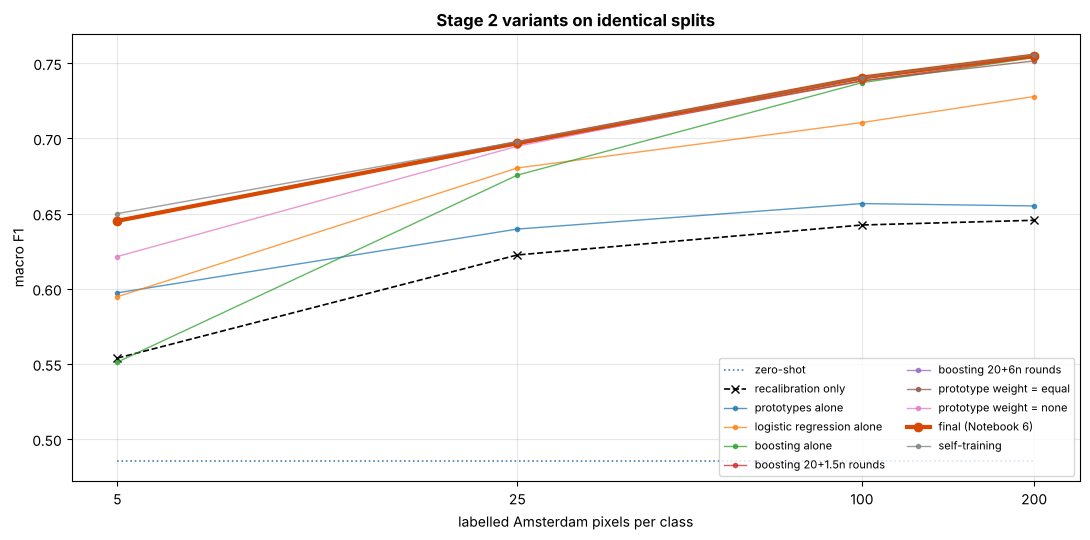

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.5))
lx = np.log2(BUDGETS)
sty = {'final (Notebook 6)': dict(color='#d94801', lw=3, marker='o'),
       'zero-shot': dict(color='steelblue', lw=1.2, ls=':'),
       'recalibration only': dict(color='black', lw=1.2, ls='--', marker='x')}
for name in vmean.index:
    ax.plot(lx, vmean.loc[name], label=name, **sty.get(name, dict(lw=1, alpha=0.75, marker='.')))
ax.set_xticks(lx); ax.set_xticklabels(BUDGETS); ax.set_xlabel('labelled Amsterdam pixels per class')
ax.set_ylabel('macro F1'); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2, loc='lower right')
ax.set_title('Stage 2 variants on identical splits', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'evidence_transfer_variants.png', bbox_inches='tight', dpi=130); plt.show()

**Reading the variants** (mean macro F1 over n = 5, 25, 100, 200; final = **0.7094**).

* **Recalibration only: 0.616 (−0.093).** Re-weighting Madrid's four probabilities fixes part of the zero-shot gap
  (0.486) but cannot move class boundaries; Amsterdam needs local features.
* **Single learners: prototypes 0.637, logistic regression 0.678, boosting 0.679.** Each is 0.03-0.07 below the
  ensemble. Logistic regression is strongest at small n (0.680 at n = 25), boosting at large n (0.754 at n = 200),
  and averaging them is best overall.
* **Boosting length 20+1.5n or 20+6n:** within ±0.001 of the final — the choice of 3 rounds per label does not matter.
* **Prototype weight:** equal 0.708 (−0.0015); none 0.703 (−0.0065), almost all of it at n = 5 (0.621 vs 0.645).
  The fading weight matters only when labels are very scarce, which is exactly what it was designed for.
* **Self-training: 0.711 (+0.0016),** inside the noise (fold standard deviations are 0.006-0.025). It adds a refit
  and a confidence threshold for no reliable gain, so we did not adopt it.

Because these alternatives were compared on Amsterdam itself, differences of a few thousandths should not be
over-read; we kept one simple rule for every budget rather than choosing the best variant per budget.

---

## 7.7 Leakage Audit

Leakage means information that would not exist when predicting a genuinely new pixel or city reaches the model or
the evaluation, so scores look better than they will be in use. Five checks:

1. **Labels hidden in features** — is a label, or a near-copy of one, among the inputs?
2. **One feature that predicts everything** — a leaked label shows up as one feature that alone matches the full model.
3. **Fit-scope** — were scaling statistics computed on test pixels?
4. **Few-shot overlap** — can an Amsterdam test pixel end up in the labelled support set?
5. **Spatial leakage** — random folds put near-identical neighbouring pixels in train and test.

Label / ID columns among the 284 features: none


/tmp/ipykernel_2273/426644615.py:4: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = pd.Series({c: abs(spearmanr(mad[c].values, mad['weighted_mean_year'].values)[0]) for c in ALL}).dropna().sort_values()



Strongest |Spearman rho| between one feature and the true construction year (Madrid):
v2_nb12_aNIR_mean      0.573
v2_nb12_aNIR_ep2000    0.572
v2_nb6_aNIR_mean       0.567
nb6_aNIR_mean          0.567
v2_nb6_aNIR_ep2000     0.563
aRed_resstd            0.554
v2_nb2_aNIR_mean       0.540
nb2_aNIR_mean          0.540


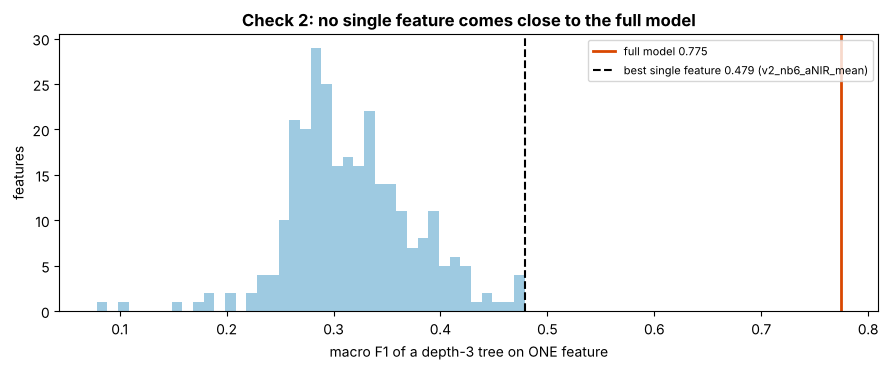

In [10]:
# ── Check 1: label columns among the features, and correlation with the label year ──
META = {'px_key', 'py_key', 'weighted_mean_year', 'age_class', 'city'}
print('Label / ID columns among the 284 features:', sorted(META & set(ALL)) or 'none')
rho = pd.Series({c: abs(spearmanr(mad[c].values, mad['weighted_mean_year'].values)[0]) for c in ALL}).dropna().sort_values()
print('\nStrongest |Spearman rho| between one feature and the true construction year (Madrid):')
print(rho[::-1].head(8).round(3).to_string())
E['max_rho'] = float(rho.max())

# ── Check 2: power of the single best feature (depth-3 tree, 3-fold, 20k pixel sample) ──
sub = np.random.default_rng(SEED).choice(len(y_mad), 20_000, replace=False)
single = pd.Series({c: f1m(y_mad[sub], cross_val_predict(
             DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED),
             X_m[sub, j:j + 1], y_mad[sub], cv=3)) for j, c in enumerate(ALL)}).sort_values()
E['single_best'] = (single.index[-1], float(single.iloc[-1]))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(single.values, bins=40, color='#9ecae1')
ax.axvline(E['all_bal']['mean'], color='#d94801', lw=2, label=f"full model {E['all_bal']['mean']:.3f}")
ax.axvline(single.iloc[-1], color='black', ls='--', label=f'best single feature {single.iloc[-1]:.3f} ({single.index[-1]})')
ax.set_xlabel('macro F1 of a depth-3 tree on ONE feature'); ax.set_ylabel('features'); ax.legend(fontsize=8)
ax.set_title('Check 2: no single feature comes close to the full model', fontweight='bold')
plt.tight_layout(); plt.show()

In [11]:
# ── Check 3: scaling statistics fitted on training folds only ─────────────────
# Our per-city scaling uses every pixel of the city (no labels). The strict version fits the median/IQR on the
# training fold only. If scores barely move, using the whole city's statistics leaks nothing that matters.
Xraw = mad[ALL].values.astype(np.float32)
t0, s_tr = time.time(), []
for tr, te in RAND3:
    st = robust_stats(Xraw[tr])
    s_tr.append(f1m(y_mad[te], lgb.LGBMClassifier(**STAGE1_PARAMS).fit(apply_stats(Xraw[tr], st), y_mad[tr])
                                .predict(apply_stats(Xraw[te], st))))
E['trainonly'] = float(np.mean(s_tr))
print(f"Check 3: whole-city scaling {E['all_bal']['mean']:.4f}  vs  train-fold-only scaling {E['trainonly']:.4f}  "
      f"(difference {E['all_bal']['mean'] - E['trainonly']:+.4f})   [{time.time()-t0:.0f}s]")

# ── Check 4: Amsterdam support / test overlap over every split of Notebook 6's protocol ──
overlap, n_splits = 0, 0
for n in (5, 25, 50, 100, 200):
    for sup, te in fewshot_splits(y_ams, n, n_repeats=2):
        overlap += len(np.intersect1d(sup, te)); n_splits += 1
E['overlap'] = (overlap, n_splits)
print(f'Check 4: support pixels that are also test pixels: {overlap} across {n_splits} splits')

Check 3: whole-city scaling 0.7746  vs  train-fold-only scaling 0.7748  (difference -0.0002)   [234s]
Check 4: support pixels that are also test pixels: 0 across 50 splits


### Check 5 — spatial leakage: random folds vs unseen districts

Pixels of the same estate look alike and share a class (Notebook 5, Section 5.6b). A random fold therefore puts a
pixel's near-twin in training, and the spatial features of a test pixel are averages over training pixels. The
honest test hides **whole districts**: the city is cut into 2 km tiles (67 × 67 pixels), whole tiles are assigned to
folds (`StratifiedGroupKFold`), and training pixels within 360 m of the test tiles (the largest neighbourhood radius,
12 pixels) are removed so no window can reach across. The maps show the folds and one fold's train / buffer / test.

135 Madrid tiles; mean training size: random 61,010, blocked 51,952 pixels


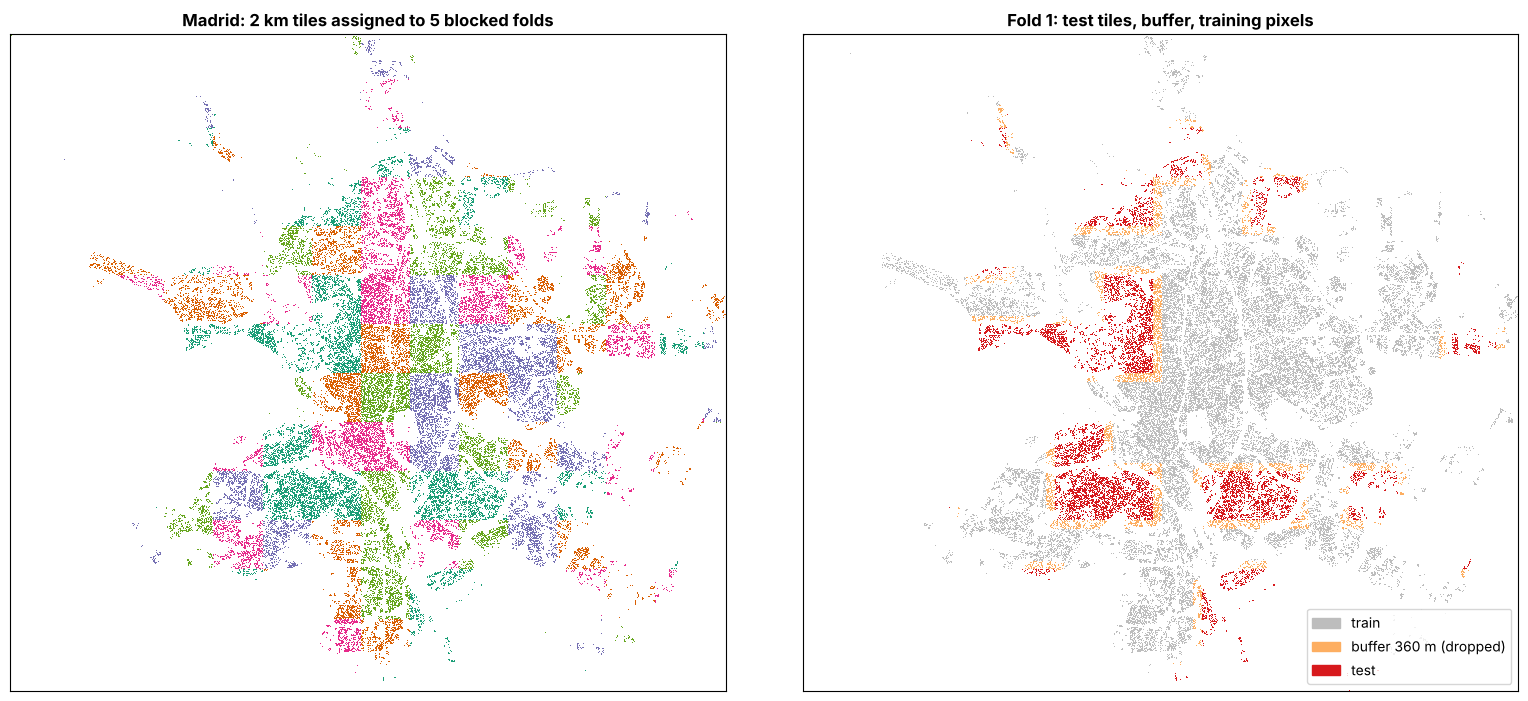

In [12]:
BLOCK, BUFFER = 67, 12
tile_m = (pix_mad[:, 0] // BLOCK) * 100_000 + (pix_mad[:, 1] // BLOCK)
tile_a = (pix_ams[:, 0] // BLOCK) * 100_000 + (pix_ams[:, 1] // BLOCK)
RAND5 = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(y_mad)), y_mad))
BLK5, fold_id = [], np.zeros(len(y_mad), int)
for k, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(y_mad)), y_mad, tile_m)):
    near = near_mask(pix_mad, te, BUFFER)
    BLK5.append((tr[~near[tr]], te)); fold_id[te] = k + 1
print(f'{len(np.unique(tile_m))} Madrid tiles; mean training size: random {np.mean([len(t) for t, _ in RAND5]):,.0f}, '
      f'blocked {np.mean([len(t) for t, _ in BLK5]):,.0f} pixels')

from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(to_grid(pix_mad, fold_id), cmap=ListedColormap(['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e']),
               origin='lower', interpolation='nearest')
axes[0].set_title('Madrid: 2 km tiles assigned to 5 blocked folds', fontweight='bold')
tr, te = BLK5[0]
role = np.full(len(y_mad), 1.0); role[tr] = 0; role[te] = 2      # 1 = buffer (removed)
axes[1].imshow(to_grid(pix_mad, role), cmap=ListedColormap(['#bdbdbd', '#fdae61', '#d7191c']), vmin=0, vmax=2,
               origin='lower', interpolation='nearest')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='#bdbdbd', label='train'), Patch(color='#fdae61', label='buffer 360 m (dropped)'),
                        Patch(color='#d7191c', label='test')], loc='lower right')
axes[1].set_title('Fold 1: test tiles, buffer, training pixels', fontweight='bold')
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(OUT_DIR / 'evidence_blocked_cv_map.png', bbox_inches='tight', dpi=120); plt.show()

In [13]:
print('Madrid, 5 folds: random vs blocked')
X_core = scaled(CORE, 'city')[0]
for key, model_fn, X, split, label in [
        ('ours_all_random',  lgbm(), X_m,    RAND5, 'ours, all 284 features, random'),
        ('ours_all_blocked', lgbm(), X_m,    BLK5,  'ours, all 284 features, blocked'),
        ('ours_core_random', lgbm(), X_core, RAND5, 'ours, no spatial features, random'),
        ('ours_core_blocked', lgbm(), X_core, BLK5, 'ours, no spatial features, blocked'),
        ('base_random',      rf,     Xb_m,   RAND5, 'baseline RF, 60 features, random'),
        ('base_blocked',     rf,     Xb_m,   BLK5,  'baseline RF, 60 features, blocked')]:
    E[key] = cv_run(model_fn, X, y_mad, split, label)

Madrid, 5 folds: random vs blocked


  ours, all 284 features, random                macro F1 = 0.7830 ± 0.0054   [392s]


  ours, all 284 features, blocked               macro F1 = 0.6338 ± 0.0287   [377s]


  ours, no spatial features, random             macro F1 = 0.6867 ± 0.0046   [257s]


  ours, no spatial features, blocked            macro F1 = 0.6150 ± 0.0304   [248s]


  baseline RF, 60 features, random              macro F1 = 0.6405 ± 0.0063   [495s]


  baseline RF, 60 features, blocked             macro F1 = 0.5881 ± 0.0252   [403s]


In [14]:
# ── Amsterdam few-shot: random vs blocked folds, ours vs the Notebook 4 baseline ──
# Baseline = Notebook 4: 60 features scaled with the Madrid scaler, nearest class prototype.
_, Xb_a = scaled(BASE, 'madrid')
def proto_baseline(sup, te):
    P = np.stack([Xb_a[sup][y_ams[sup] == c].mean(0) for c in (1, 2, 3, 4)])
    return np.linalg.norm(Xb_a[te][:, None] - P[None], axis=2).argmin(1) + 1

SH = [5, 25, 50, 100, 200]
ams_cmp = {}
t0 = time.time()
for mode, kw in [('random', {}), ('blocked', dict(groups=tile_a, pix=pix_ams, buffer=BUFFER))]:
    for who in ('ours', 'baseline'):
        res = []
        for n in SH:
            s = []
            for sup, te in fewshot_splits(y_ams, n, n_repeats=2, **kw):
                pred = (adapt_to_city(stage1, X_a, sup, y_ams[sup], n)[te].argmax(1) + 1) if who == 'ours' \
                       else proto_baseline(sup, te)
                s.append(f1m(y_ams[te], pred))
            res.append(np.mean(s))
        ams_cmp[(who, mode)] = res
    print(f'  {mode} done [{time.time()-t0:.0f}s]')
ams_tab = pd.DataFrame(ams_cmp, index=pd.Index(SH, name='labels per class')).T
ams_tab['average'] = ams_tab.mean(axis=1)
E['ams_tab'] = ams_tab

  random done [287s]


  blocked done [574s]


,random folds,unseen districts (blocked),drop
"ours, all features",0.7830,0.6338,-0.1492
"ours, no spatial features",0.6867,0.6150,-0.0718
baseline RF (NB3 features),0.6405,0.5881,-0.0524


,labels per class,5,25,50,100,200,average
ours,random,0.6451,0.6969,0.7097,0.7404,0.7551,0.7094
baseline,random,0.5745,0.6009,0.6158,0.6161,0.6138,0.6042
ours,blocked,0.6359,0.6958,0.6989,0.7093,0.7233,0.6926
baseline,blocked,0.5270,0.5998,0.5953,0.6111,0.6091,0.5885


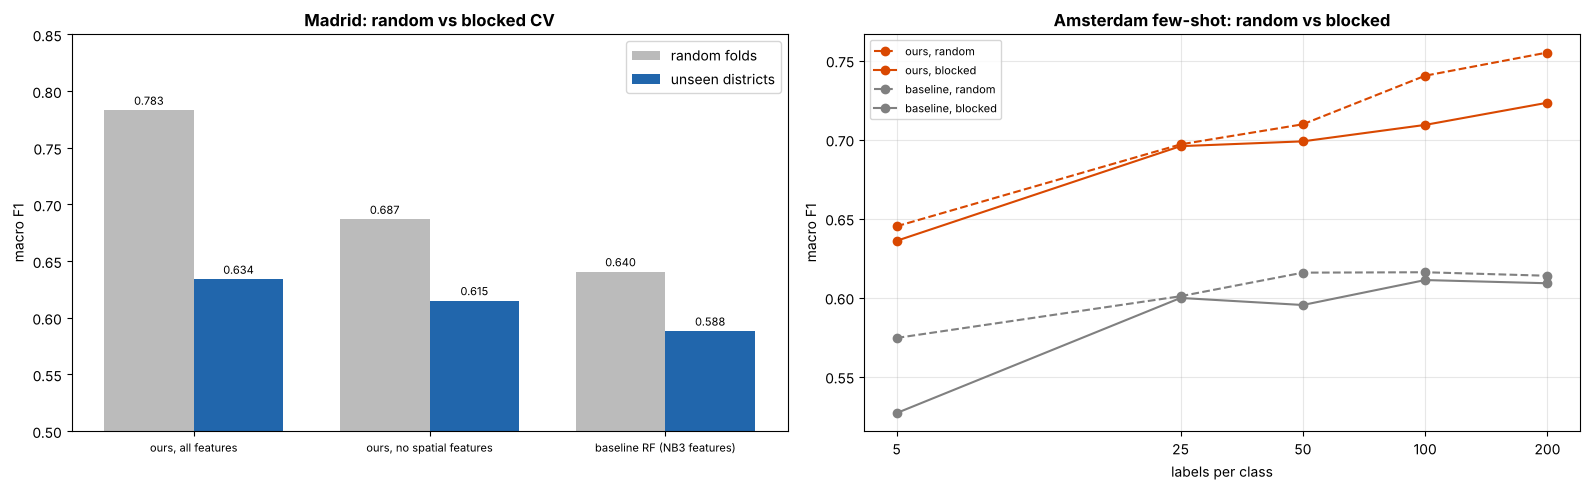

In [15]:
# ── Leakage audit: results ─────────────────────────────────────────────────────
mad_tab = pd.DataFrame({
    'random folds':  [E['ours_all_random']['mean'], E['ours_core_random']['mean'], E['base_random']['mean']],
    'unseen districts (blocked)': [E['ours_all_blocked']['mean'], E['ours_core_blocked']['mean'], E['base_blocked']['mean']]},
    index=['ours, all features', 'ours, no spatial features', 'baseline RF (NB3 features)'])
mad_tab['drop'] = mad_tab.iloc[:, 1] - mad_tab.iloc[:, 0]
display(mad_tab.style.format('{:+.4f}', subset=['drop']).format('{:.4f}', subset=mad_tab.columns[:2])
        .set_caption('Madrid macro F1, 5 folds'))
display(ams_tab.style.format('{:.4f}').set_caption('Amsterdam few-shot macro F1 (5 folds x 2 repeats)'))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(3); w = 0.38
axes[0].bar(x - w / 2, mad_tab.iloc[:, 0], w, color='#bbbbbb', label='random folds')
axes[0].bar(x + w / 2, mad_tab.iloc[:, 1], w, color='#2166ac', label='unseen districts')
for xi in x:
    axes[0].text(xi - w / 2, mad_tab.iloc[xi, 0] + 0.005, f'{mad_tab.iloc[xi, 0]:.3f}', ha='center', fontsize=8)
    axes[0].text(xi + w / 2, mad_tab.iloc[xi, 1] + 0.005, f'{mad_tab.iloc[xi, 1]:.3f}', ha='center', fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(mad_tab.index, fontsize=8); axes[0].set_ylim(0.5, 0.85)
axes[0].set_ylabel('macro F1'); axes[0].legend(); axes[0].set_title('Madrid: random vs blocked CV', fontweight='bold')
lx = np.log2(SH)
for (who, mode), c, ls in [(('ours', 'random'), '#d94801', '--'), (('ours', 'blocked'), '#d94801', '-'),
                           (('baseline', 'random'), 'grey', '--'), (('baseline', 'blocked'), 'grey', '-')]:
    axes[1].plot(lx, ams_cmp[(who, mode)], color=c, ls=ls, marker='o', label=f'{who}, {mode}')
axes[1].set_xticks(lx); axes[1].set_xticklabels(SH); axes[1].set_xlabel('labels per class')
axes[1].set_ylabel('macro F1'); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
axes[1].set_title('Amsterdam few-shot: random vs blocked', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'evidence_leakage.png', bbox_inches='tight', dpi=130); plt.show()

audit = {'label_columns_in_features': sorted(META & set(ALL)), 'max_abs_spearman_feature_vs_year': E['max_rho'],
         'best_single_feature': E['single_best'], 'full_model_3fold': E['all_bal']['mean'],
         'trainonly_scaling_3fold': E['trainonly'], 'support_test_overlap': E['overlap'],
         'madrid': mad_tab.round(4).to_dict(),
         'amsterdam': {f'{who}, {mode}': dict(zip(map(str, SH), np.round(v, 4).tolist())) for (who, mode), v in ams_cmp.items()}}
json.dump(audit, open(OUT_DIR / 'leakage_audit_nb7.json', 'w'), indent=1, default=str)

**Verdict.**

* **Checks 1-4 are clean.** No label or ID column is an input. The strongest single feature correlates with the
  construction year at |ρ| = 0.57, and alone scores 0.479 macro F1 against 0.775 for the full model, which is not the
  pattern of a leaked label. Fitting the scaling on training folds only changes the score by −0.0002. No Amsterdam
  test pixel was ever in a support set (0 overlaps in 50 splits).
* **Check 5 finds the one real issue: random CV is spatially optimistic in Madrid.** On unseen 2 km districts our
  model falls from **0.783 to 0.634** (−0.149). Without spatial features the fall is −0.072 and for the baseline RF
  −0.052, so most of the optimism comes from the neighbourhood features averaging over near-twins of the test pixel.
* **The improvement is still real.** Under the same blocked test our model beats the baseline by **+0.046** in Madrid
  (0.634 vs 0.588), and spatial features still add +0.019 (0.634 vs 0.615). In Amsterdam the gap is larger: averaged
  over 5-200 labels, ours **0.693 vs baseline 0.588** on unseen districts.
* **Amsterdam few-shot holds up well** (random 0.709 → blocked 0.693 on average; 0.696 at n = 25), because Stage 2 is
  refit around labels spread over the city. **The blocked numbers are the honest estimate for a new district;**
  the random-fold 0.783 is an upper bound.

---

## 7.8 Summary: each decision and its evidence

All values below are computed in this notebook (or in the Notebook 5 section named).

In [16]:
ab = E['ablation'].set_index(['feature set', 'scaling'])
v  = E['variants'].mean(axis=1)
summary = pd.DataFrame([
    ('Per-slot haze filter + median of scenes', 'NB3 first-scene rule', 'NB5 §5.2b', 'more clean pixel-years, lower jitter', '', ''),
    ('City-year anomaly', 'raw reflectance', 'NB5 §5.4b', 'same-class city gap (mean |SD|)', '', ''),
    ('Spatial context features', 'none', 'NB5 §5.6b', 'neighbours share class vs chance', '', ''),
    ('LightGBM', 'Random Forest (60 feat.)', '7.2', 'Madrid CV', E['lgbm_base']['mean'], E['rf_base']['mean']),
    ("class_weight='balanced'", 'no weights', '7.3', 'Madrid CV', E['all_bal']['mean'], E['all_nobal']['mean']),
    ('All feature groups', 'NB3 60 features', '7.4', 'Madrid CV',
     ab.loc[('+ spatial v2 (final)', 'city'), 'Madrid CV'], ab.loc[('baseline (NB3, 60)', 'city'), 'Madrid CV']),
    ('All feature groups', 'NB3 60 features', '7.4', 'Amsterdam 25-shot',
     ab.loc[('+ spatial v2 (final)', 'city'), '25-shot'], ab.loc[('baseline (NB3, 60)', 'city'), '25-shot']),
    ('Per-city scaling', 'Madrid scaler', '7.5', 'Amsterdam zero-shot',
     ab.loc[('+ spatial v2 (final)', 'city'), 'zero-shot'], ab.loc[('+ spatial v2 (final)', 'madrid'), 'zero-shot']),
    ('Per-city scaling', 'Madrid scaler', '7.5', 'Amsterdam 25-shot',
     ab.loc[('+ spatial v2 (final)', 'city'), '25-shot'], ab.loc[('+ spatial v2 (final)', 'madrid'), '25-shot']),
    ('3-learner ensemble', 'recalibration only', '7.6', 'Ams. mean over n', v['final (Notebook 6)'], v['recalibration only']),
    ('3-learner ensemble', 'best single learner', '7.6', 'Ams. mean over n', v['final (Notebook 6)'],
     v[['prototypes alone', 'logistic regression alone', 'boosting alone']].max()),
    ('No self-training', 'self-training', '7.6', 'Ams. mean over n', v['final (Notebook 6)'], v['self-training']),
    ('Gain is real (not leakage)', 'baseline, same blocked test', '7.7', 'Madrid, unseen districts',
     E['ours_all_blocked']['mean'], E['base_blocked']['mean']),
    ('Gain is real (not leakage)', 'baseline, same blocked test', '7.7', 'Ams. average, unseen districts',
     E['ams_tab'].loc[('ours', 'blocked'), 'average'], E['ams_tab'].loc[('baseline', 'blocked'), 'average']),
], columns=['decision', 'alternative', 'where', 'metric', 'chosen', 'alternative value'])
num = pd.to_numeric(summary['chosen'], errors='coerce') - pd.to_numeric(summary['alternative value'], errors='coerce')
summary['difference'] = num
summary.to_csv(OUT_DIR / 'decision_evidence_summary.csv', index=False)
fmt = lambda x: f'{x:.4f}' if isinstance(x, float) else x
display(summary.style.format({'chosen': fmt, 'alternative value': fmt, 'difference': lambda x: '' if pd.isna(x) else f'{x:+.4f}'}, na_rep=''))

,decision,alternative,where,metric,chosen,alternative value,difference
0,Per-slot haze filter + median of scenes,NB3 first-scene rule,NB5 §5.2b,"more clean pixel-years, lower jitter",,,
1,City-year anomaly,raw reflectance,NB5 §5.4b,same-class city gap (mean |SD|),,,
2,Spatial context features,none,NB5 §5.6b,neighbours share class vs chance,,,
3,LightGBM,Random Forest (60 feat.),7.2,Madrid CV,0.6512,0.6367,+0.0144
4,class_weight='balanced',no weights,7.3,Madrid CV,0.7746,0.7722,+0.0025
5,All feature groups,NB3 60 features,7.4,Madrid CV,0.7746,0.6512,+0.1235
6,All feature groups,NB3 60 features,7.4,Amsterdam 25-shot,0.6942,0.6537,+0.0405
7,Per-city scaling,Madrid scaler,7.5,Amsterdam zero-shot,0.4856,0.5058,-0.0202
8,Per-city scaling,Madrid scaler,7.5,Amsterdam 25-shot,0.6942,0.6933,+0.0009
9,3-learner ensemble,recalibration only,7.6,Ams. mean over n,0.7094,0.6161,+0.0933


Every row points to the cell that produced it, so a question such as *"why not a Random Forest?"* or *"is the score
inflated by leakage?"* can be answered by re-running one section. The CSV `results/decision_evidence_summary.csv`
holds the same table.